In [2]:
import numpy as np
import discretisedfield as df
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import os 
from matplotlib.colors import hsv_to_rgb
import matplotlib.patches as patches
import matplotlib as mpl
from scipy.ndimage import map_coordinates

from scripts.read_field import file_to_array, read_dir, draw_field, animate_field, cmap, cmap_chi
from scripts.mm.fit import fit
from scripts.mm.experiment import Experiment
from scripts.scientific import apply

mpl.rcParams.update(mpl.rcParamsDefault)
apply()

### Tests

In [60]:
X, Y = np.meshgrid(np.linspace(-5, 5, 500), np.linspace(-5,5, 500))
r = np.sqrt(X ** 2 + Y ** 2)
theta = 2 * np.arctan(np.sinh(1)/np.sinh(r))
phi = np.arctan2(Y, X) * 2
m = np.stack([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)]).transpose((1,2,0))
print(m.shape)

(500, 500, 3)


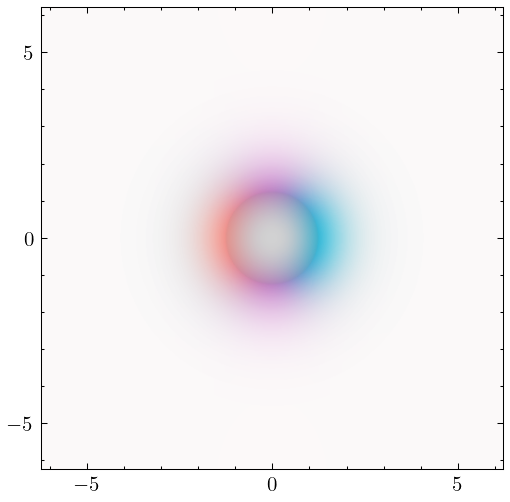

In [61]:
fig, ax = plt.subplots()
draw_field(ax, m, mode='spirality', spirality_contrast=2)
plt.show()

In [6]:
import numpy as np

X, Y = np.meshgrid(
    np.linspace(-5, 5, 500),
    np.linspace(-5, 5, 500)
)

rho = np.sqrt(X**2 + Y**2)
alpha = np.arctan2(Y, X)

rot = np.pi / 2

# Triangle directions
a1 = np.cos(alpha - rot)
a2 = np.cos(alpha - rot - 2*np.pi/3)
a3 = np.cos(alpha - rot - 4*np.pi/3)

# Smoothness parameter
# larger k -> sharper triangle
# smaller k -> smoother corners
k = 10

# Smooth max
r_tri = rho * (
    np.log(
        np.exp(k*a1) +
        np.exp(k*a2) +
        np.exp(k*a3)
    ) / k
)

r_tri = np.abs(r_tri)
r_tri = np.clip(r_tri, 1e-6, None)

# Skyrmion profile
theta = 2 * np.arctan(np.sinh(1) / np.sinh(r_tri))

alpha += np.pi
# phi = alpha * 2
c = 5
phi = np.zeros_like(alpha)
for i in range(6):
    phi += np.pi / 3 * np.tanh(c * (alpha - np.pi * i / 3 - np.pi /6))

# # Q = 2 winding
# phi = (2 * np.pi / 3)  * ((alpha >= np.pi / 6 ) & (alpha <  np.pi / 2 )) +\
#       (4 * np.pi / 3)  * ((alpha >= np.pi / 2 ) & (alpha <  5 * np.pi / 6 )) +\
#       (6 * np.pi / 3)  * ((alpha >= 5 * np.pi / 6 ) & (alpha <= np.pi) | (alpha >= -np.pi ) & (alpha < -5 * np.pi / 6)) +\
#       (8 * np.pi / 3)  * ((alpha >= -5 * np.pi / 6 ) & (alpha <  -np.pi /2 )) +\
#       (10 * np.pi / 3) * ((alpha >= -np.pi /2 ) & (alpha <  -np.pi / 6 )) +\
#       (12 * np.pi / 3) * ((alpha >= - np.pi / 6 ) & (alpha < np.pi /6))

# Magnetization
m = np.stack([
    np.sin(theta) * np.cos(phi),
    np.sin(theta) * np.sin(phi),
    np.cos(theta)
]).transpose((1, 2, 0))

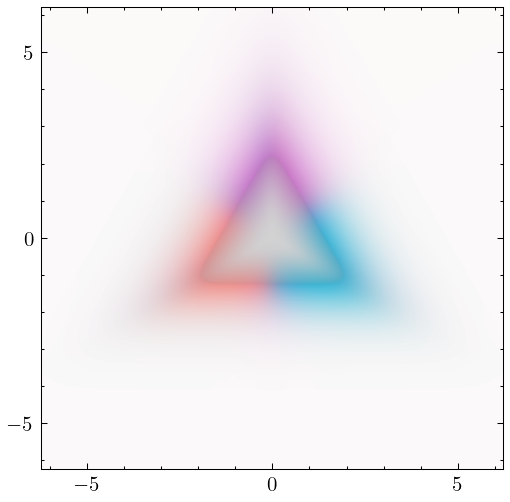

In [ ]:
fig, ax = plt.subplots()
draw_field(ax, m, mode='spirality', spirality_contrast=2)

### Draw

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------
# CREATE SKYRMION
# ---------------------------------------------------

extent = 1.5
X, Y = np.meshgrid(
    np.linspace(-extent, extent, 200),
    np.linspace(-extent, extent, 200)
)

r = np.sqrt(X**2 + Y**2)

w = 4
theta = 2 * np.arctan(
    np.sinh(w)/np.sinh(w * r)
)

phi = np.arctan2(Y, X) * 2

m = np.stack([
    np.sin(theta) * np.cos(phi),
    np.sin(theta) * np.sin(phi),
    np.cos(theta)
]).transpose((1,2,0))

# ---------------------------------------------------
# HIDDEN CARTESIAN AXIS
# ---------------------------------------------------

fig = plt.figure(figsize=(6,6))

ax_hidden = fig.add_axes([0,0,1,1])

im = draw_field(ax_hidden, m, mode='spirality')
ax_hidden.remove()

# force rendering
fig.canvas.draw()
fig.set_size_inches(3,3)

# extract RGBA image
img = im.get_array()

# ---------------------------------------------------
# POLAR AXIS
# ---------------------------------------------------

ax = fig.add_subplot(
    111,
    projection='polar',
)

# ---------------------------------------------------
# POLAR GRID
# ---------------------------------------------------

N = img.shape[0]

R = np.linspace(0, extent*np.sqrt(2), N)
A = np.linspace(-np.pi, np.pi, N)

AA, RR = np.meshgrid(A, R)

# Polar -> Cartesian
XX = RR * np.cos(AA)
YY = RR * np.sin(AA)

# ---------------------------------------------------
# Convert to image coordinates
# ---------------------------------------------------

ix = (XX + extent) / (2 * extent) * (N - 1)
iy = (YY + extent) / (2 * extent) * (N - 1)

# ---------------------------------------------------
# Interpolated sampling
# ---------------------------------------------------

if img.ndim == 2:

    polar_img = map_coordinates(
        img,
        [iy, ix],
        order=1,
        mode='nearest'
    )

else:
    # RGB/RGBA image
    channels = []

    for c in range(img.shape[2]):
        channels.append(
            map_coordinates(
                img[:,:,c],
                [iy, ix],
                order=1,
                mode='nearest'
            )
        )

    polar_img = np.stack(channels, axis=-1)

# ---------------------------------------------------
# DISPLAY
# ---------------------------------------------------

ax.pcolormesh(
    AA,
    RR,
    np.zeros((N, N)),
    color=polar_img.reshape(-1, polar_img.shape[-1]),
    shading='nearest'
)

ax.set_ylim([0, extent])
ax.set_xticks(
    [0,             np.pi / 2,              np.pi,              3 * np.pi / 2], 
    [
        r"$\begin{matrix}\eta = 0 \\ \text{N\'eel} \end{matrix}$",
        r"$\begin{matrix}\eta = \pi / 2 \\ \text{Bloch} \end{matrix}$",
        r"$\begin{matrix}\eta = \pi \\ \text{N\'eel} \end{matrix}$",
        r"$\begin{matrix}\eta = -\pi / 2 \\ \text{Bloch} \end{matrix}$"])
# add padding for label position 
offset = 0.1
ax.set_yticks(
    [0, 1 - offset, extent - offset],
    ["$m_z = -1$", 
     "$m_z = 0$", 
     "$m_z = 1$"]
)
ax.set_yticklabels(ax.get_yticklabels(), ha='center')
xticklabels = ax.get_xticklabels()
xticklabels[0].set_horizontalalignment('left')
xticklabels[1].set_verticalalignment('bottom')
xticklabels[2].set_horizontalalignment('right')
xticklabels[3].set_verticalalignment('top')
yticklabels = ax.get_yticklabels()
yticklabels[2].set_verticalalignment('top')
yticklabels[2].set_y(yticklabels[2].get_position()[1] - 20)
yticklabels[1].set_verticalalignment('top')
yticklabels[0].set_verticalalignment('center')
ax.set_rlabel_position(90)
ax.tick_params(axis='y', pad=100)
# ---------------------------------------------------
# Smooth colored ring with pcolormesh
# ---------------------------------------------------

ring_r0 = 1.0
ring_width = 0.05

# angular resolution
Nphi = 1000
Nr = 2

phi_ring = np.linspace(0, 2*np.pi, Nphi)

# radial boundaries of ring
r_ring = np.array([
    ring_r0 - ring_width,
    ring_r0
])

PP, RR = np.meshgrid(phi_ring, r_ring)

# ---------------------------------------------------
# Anchor colors
# ---------------------------------------------------

anchors = np.array([
    0,
    np.pi/2,
    np.pi,
    3*np.pi/2,
    2*np.pi
])

anchor_colors = np.array([
    cmap(0.75),
    cmap_chi(0.5),
    cmap(0.25),
    cmap_chi(0.5),
    cmap(0.75)
])

# interpolate RGBA channels
ring_colors = np.zeros((Nphi, 4))

for i in range(4):
    ring_colors[:, i] = np.interp(
        phi_ring,
        anchors,
        anchor_colors[:, i]
    )

# pcolormesh expects cell colors
C = ring_colors[:-1][None, :, :]

# ax.pcolormesh(
#     PP,
#     RR,
#     np.zeros((1, Nphi-1)),
#     color=C.reshape(-1, 4),
#     shading='flat'
# )

phi = np.linspace(0, 2*np.pi, 100)
r_one = np.ones_like(phi)

for line in [
        # r_one / 2,
        r_one, 
        # r_one * (extent + 1) / 2, 
        # r_one * extent - offset
    ]:
    ax.plot(
        phi,
        line,
        color='black',
        alpha=0.5,
        linewidth=1/4
    )

for phi in np.arange(0, 2 * np.pi, np.pi / 2):
    ax.plot([phi, phi], [0, extent],
        color='black',
        alpha=0.5,
        linewidth=1/4 
    )

ax.grid()

# ---------------------------------------------------
# Magnetization arrows at r = 1
# ---------------------------------------------------

# 8 principal directions + 4 intermediate
angles = np.linspace(0, 2*np.pi, 16, endpoint=False)

r0 = 1.0

# Q = 2 winding
phi_m = 2 * angles

# in-plane magnetization direction
u = np.cos(phi_m)
v = np.sin(phi_m)

# arrow length
L = 0.18

# Angles don't perfectly map to polar coordinates 
# Introduction of a small shift at poles pi / 2 and -pi /2 to make quiver parallel to domain wall
distorted_angles = angles + np.sin(angles) * 0.56
vr = (
    u * np.cos(distorted_angles) +
    v * np.sin(distorted_angles)
)

vt = (
    -u * np.sin(distorted_angles) +
     v * np.cos(distorted_angles)
)


ax.quiver(
    angles,
    np.full_like(angles, r0),
    vt,                 # angular component
    vr,                 # radial component
    angles='xy',
    scale_units='xy',
    scale=4,
    width=0.008,
    color='black',
    zorder=20,
    pivot='mid'
)

plt.savefig('article/images/palette.pdf')